# Decision rules in a simulated research process

**U of T Fall School on Agentic AI in Science · Amey Pore**

This lab compares a fixed protocol, a state-aware rule, a language model using current information, the same model supplied with notes from earlier runs, and a reinforcement-learning (RL) controller.

The simulator defines an eight-step process in which actions affect nutrient, stress, and later states. The RL controller learns which action to choose for each simulated state.

**Benchmark scope:** In this simulator, RL has a higher mean reward than the two fixed protocols and the stated state-aware rule across 1,000 test seeds. The language-model comparison uses one paired seed, so it does not establish typical performance or general superiority.

### Learning objectives
1. Reproduce the reference benchmark and examine its fixed rules.
2. Vary `TRY_TRAIN_EPISODES` and compare policy returns.
3. Use the configured language-model API to summarize earlier runs as notes.
4. Compare the language model with and without those notes on the same task.

All experiments in this notebook are simulated. The process is not a physical or biological model, and its actions are not laboratory recommendations.

## 0. Setup and live API check

Configure the OpenRouter model and API key as described in `README.md`. Use the ignored `api_config_local.py` file for a key that must not be shared. The next code cell sends one request to verify the configuration. The simulator and RL sections run locally; the language-model sections require API access.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from simulator import ACTIONS, HORIZON, SyntheticProcess, train_q_learning, run_episode, evaluate_many, evaluate_custom_rule, report
from llm_client import connection_check, ask_json, ask_text

SEED = 7
TRAIN_EPISODES = 12_000
EVAL_SEEDS = range(10_000, 11_000)  # 1,000 never used for training

print('The LLM connection is required. If it fails, ask the tutorial organizers for configuration help.')
model_info = connection_check()

The LLM connection is required. If it fails, ask the tutorial organizers for configuration help.
Live model connection: openai_compatible / openai/gpt-5.6-luna
Model replied: READY


## 1. Sequential decisions

The process has **eight actions**. The state is `(step, nutrient, stress)`.

| Action | Immediate effect | Effect on subsequent states |
|---|---|---|
| **REST** | Increases nutrient, reduces stress, produces no output | Can support later actions |
| **STEADY** | Produces output when nutrient is available | Uses one nutrient and reduces stress |
| **BOOST** | Can produce more output | Uses two nutrient and increases stress; the outcome depends on state |

A random disturbance may remove nutrient at each step. The final reward is **4 × production − action costs − final stress penalty**. The terminal stress penalty can make an intermediate production gain reduce the final return.

Because each action changes the state for later decisions, the task is to choose actions over a fixed number of steps.

In [2]:
example_total, example_trace = run_episode('Fixed alternating', seed=2026)
print('One example of a fixed action schedule:')
display(pd.DataFrame(example_trace)[['step', 'before', 'action', 'after', 'gain', 'reward']])
print('Final score:', round(example_total, 2))

One example of a fixed action schedule:


,step,before,action,after,gain,reward
0,1,"(0, 4, 0)",BOOST,"(1, 2, 2)",6,22.0
1,2,"(1, 2, 2)",REST,"(2, 4, 0)",0,-0.5
2,3,"(2, 4, 0)",BOOST,"(3, 2, 2)",6,22.0
3,4,"(3, 2, 2)",REST,"(4, 4, 0)",0,-0.5
4,5,"(4, 4, 0)",BOOST,"(5, 2, 2)",6,22.0
5,6,"(5, 2, 2)",REST,"(6, 4, 0)",0,-0.5
6,7,"(6, 4, 0)",BOOST,"(7, 2, 2)",0,-2.0
7,8,"(7, 2, 2)",REST,"(8, 4, 0)",0,-0.5


Final score: 62.0


## 2. Benchmark policies

The benchmark evaluates five rules: random, always STEADY, fixed BOOST/REST alternation, a state-aware rule, and Q-learning. The state-aware rule uses nutrient and stress to select actions; it is fixed and does not change during training.

Q-learning is trained for **12,000 simulated runs**. Language-model weights are unchanged. The rules are tested on **1,000 simulator seeds** not used for training.

In [3]:
Q_reference, training_history = train_q_learning(TRAIN_EPISODES, seed=SEED)
policies = {
    'RL': Q_reference,
    'State-aware rule': None,
    'Fixed alternating': None,
    'Always STEADY': None,
    'Random': None,
}
score_arrays = evaluate_many(policies, seeds=EVAL_SEEDS)
reference_table = report(score_arrays)
display(reference_table)

paired_difference = score_arrays['RL'] - score_arrays['State-aware rule']
ci_half = 1.96 * paired_difference.std(ddof=1) / np.sqrt(len(paired_difference))
print(f'RL vs state-aware rule: +{paired_difference.mean():.2f} reward points')
print(f'Approximate paired 95% CI: [{paired_difference.mean()-ci_half:.2f}, {paired_difference.mean()+ci_half:.2f}]')

,policy,mean_return,sd_across_runs,se_mean,n
0,RL,75.57,12.30,0.39,1000
1,State-aware rule,67.48,17.03,0.54,1000
2,Fixed alternating,64.83,23.32,0.74,1000
3,Random,28.97,18.07,0.57,1000
4,Always STEADY,14.25,7.35,0.23,1000


RL vs state-aware rule: +8.09 reward points
Approximate paired 95% CI: [7.11, 9.07]


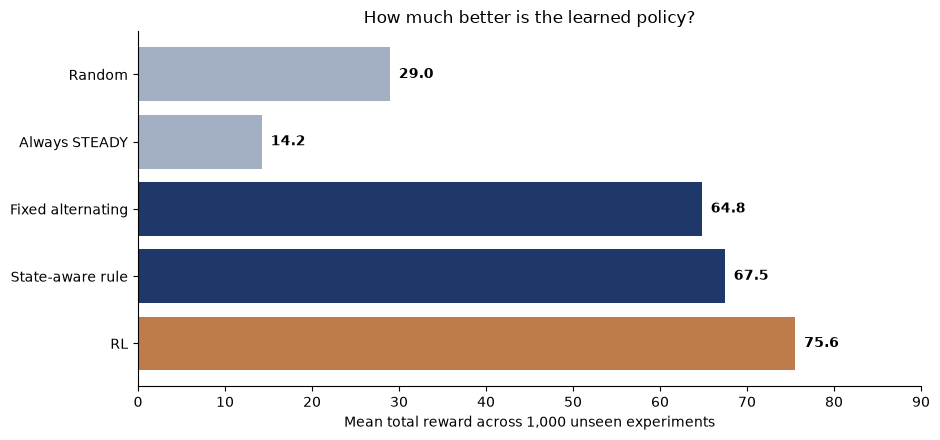

In [4]:
order = ['Random','Always STEADY','Fixed alternating','State-aware rule','RL']
means = [score_arrays[k].mean() for k in order]
colors = ['#a3b0c3','#a3b0c3','#1e3869','#1e3869','#bd7c49']
fig, ax = plt.subplots(figsize=(9.5,4.5))
ax.barh(order, means, color=colors)
ax.invert_yaxis()
for i,mean in enumerate(means): ax.text(mean+1, i, f'{mean:.1f}', va='center', weight='bold')
ax.set_xlim(0, 90)
ax.set_xlabel('Mean total reward across 1,000 unseen experiments')
ax.set_title('How much better is the learned policy?')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.show()

The fixed alternating schedule and state-aware rule provide comparison results. In this simulator, Q-learning has a higher mean reward because it uses the state and the number of steps remaining. This result applies only to this simulator and test procedure.

## 3. Design and test a rule

Edit only `participant_rule` in the next cell. It receives `(step, nutrient, stress)` and must return `REST`, `STEADY`, or `BOOST`. Run the cell to evaluate the rule on the same 1,000 held-out seeds used for the reference policies. This exercise makes no API calls.

Keep the reference state-aware rule unchanged so that your result can be compared with the reported baseline.

In [ ]:
# Participant exercise: edit only the function below, then run this cell.
# Return exactly one action label: "REST", "STEADY", or "BOOST".
def participant_rule(state):
    step, nutrient, stress = state
    if nutrient >= 3 and stress == 0:
        return "BOOST"
    if nutrient == 0 or stress >= 2:
        return "REST"
    return "STEADY"

participant_scores = evaluate_custom_rule(participant_rule, seeds=EVAL_SEEDS)
participant_comparison = report({
    'Participant rule': participant_scores,
    'Reference state-aware rule': score_arrays['State-aware rule'],
    'RL reference': score_arrays['RL'],
})
display(participant_comparison)

participant_total, participant_trace = run_episode(
    'Custom rule', seed=2026, custom_rule=participant_rule
)
print('Participant-rule score on example seed:', round(participant_total, 2))
display(pd.DataFrame(participant_trace)[['step', 'before', 'action', 'after', 'gain', 'reward']])

## 4. Training-length exercise

The reference Q-policy was trained with `TRAIN_EPISODES = 12_000`.

Set `TRY_TRAIN_EPISODES` to `3_000` or `12_000` and run the next cell. The chart compares this policy with the reference policy and the state-aware rule. This simulator-only exercise makes no API calls.

This exercise examines how the number of training runs relates to reward.

,policy,mean_reward
0,RL after 100 runs,65.90
1,"RL after 12,000 runs",75.57
2,State-aware handwritten rule,67.48


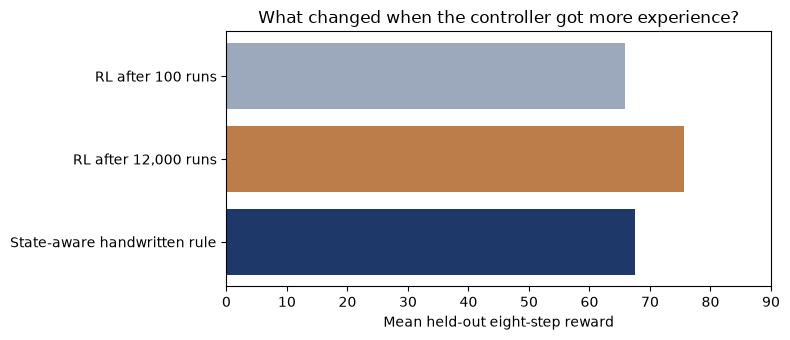

In [5]:
TRY_TRAIN_EPISODES = 100  # CHANGE ME: try 500, 3_000, 12_000

Q_changed, _changed_training = train_q_learning(TRY_TRAIN_EPISODES, seed=SEED)
changed = evaluate_many({'RL':Q_changed}, seeds=EVAL_SEEDS)['RL']
comparison = pd.DataFrame({
    'policy': [f'RL after {TRY_TRAIN_EPISODES:,} runs',
               f'RL after {TRAIN_EPISODES:,} runs',
               'State-aware handwritten rule'],
    'mean_reward': [changed.mean(), score_arrays['RL'].mean(),
                    score_arrays['State-aware rule'].mean()],
})
display(comparison.round(2))
plt.figure(figsize=(8,3.5))
plt.barh(comparison.policy, comparison.mean_reward, color=['#9ca9bd','#bc7d4b','#1e3869'])
plt.gca().invert_yaxis(); plt.xlabel('Mean held-out eight-step reward')
plt.xlim(0,90);plt.title('What changed when the controller got more experience?')
plt.tight_layout();plt.show()

### Results across training seeds

For each training length, this cell trains policies from the beginning using **five random seeds**. Each policy is tested on separate seeds. The table reports the average and spread across training seeds. This analysis uses no model calls.

,mean,std
training_episodes,,
100,62.66,3.46
500,68.56,1.68
3000,73.90,1.29
12000,75.95,0.49


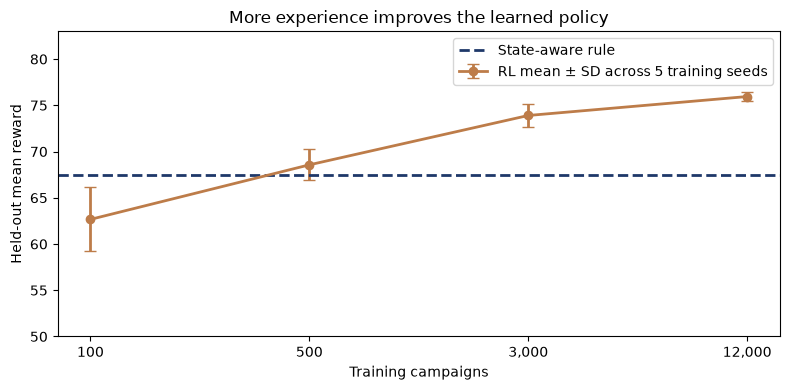

In [6]:
CHECKPOINTS = [100,500,3000,12000]
TRAINING_SEEDS = [7,11,23,31,42]
progress_rows=[]
for episodes in CHECKPOINTS:
    for training_seed in TRAINING_SEEDS:
        q,_ = train_q_learning(episodes, seed=training_seed)
        # Separate held-out evaluation seeds from the reference run.
        outcome=evaluate_many({'RL':q},seeds=range(12000,12500))['RL']
        progress_rows.append({'training_episodes':episodes,
                              'training_seed':training_seed,
                              'heldout_mean':outcome.mean()})
progress=pd.DataFrame(progress_rows)
progress_summary=progress.groupby('training_episodes').heldout_mean.agg(['mean','std'])
display(progress_summary.round(2))

x=np.arange(len(CHECKPOINTS))
fig,ax=plt.subplots(figsize=(8,4))
ax.errorbar(x,progress_summary['mean'],yerr=progress_summary['std'],color='#bd7c49',
            fmt='o-',capsize=4,lw=2,label='RL mean ± SD across 5 training seeds')
ax.axhline(score_arrays['State-aware rule'].mean(),ls='--',lw=2,color='#1e3869',label='State-aware rule')
ax.set_xticks(x,[f'{v:,}' for v in CHECKPOINTS]);ax.set_xlabel('Training campaigns')
ax.set_ylabel('Held-out mean reward');ax.set_ylim(50,83)
ax.set_title('More experience improves the learned policy')
ax.legend();plt.tight_layout();plt.show()

## 5. Creating notes from earlier runs

A decision system can use notes from earlier runs as well as a learned rule. In this section, a language model summarizes earlier simulated runs as notes.

The language model receives **six earlier runs**, whereas RL is trained on thousands of simulated runs. The methods therefore use different amounts of prior data. This comparison shows two procedures and does not establish that one is generally better.

In [7]:
HISTORICAL_PROTOCOLS = [
    ('Always STEADY',301),('Fixed alternating',302),('State-aware rule',303),
    ('Fixed alternating',304),('State-aware rule',305),('Always STEADY',306),
]
experience_rows=[]
for name,seed in HISTORICAL_PROTOCOLS:
    total,trace=run_episode(name,seed=seed)
    experience_rows.append({
        'protocol':name, 'seed':seed,'total_reward':round(total,2),
        'decisions':[r['action'] for r in trace],
        'observed_outcomes':[(r['before'],r['action'],r['gain'],r['after']) for r in trace]
    })
display(pd.DataFrame([{k:v for k,v in r.items() if k!='observed_outcomes'}
                      for r in experience_rows]))

,protocol,seed,total_reward,decisions
0,Always STEADY,301,2.4,"[STEADY, STEADY, STEADY, STEADY, STEADY, STEAD..."
1,Fixed alternating,302,33.0,"[BOOST, REST, BOOST, REST, BOOST, REST, BOOST,..."
2,State-aware rule,303,83.8,"[BOOST, STEADY, REST, BOOST, REST, BOOST, REST..."
3,Fixed alternating,304,57.0,"[BOOST, REST, BOOST, REST, BOOST, REST, BOOST,..."
4,State-aware rule,305,81.0,"[BOOST, REST, BOOST, REST, BOOST, REST, BOOST,..."
5,Always STEADY,306,26.4,"[STEADY, STEADY, STEADY, STEADY, STEADY, STEAD..."


In [8]:
memory_prompt=f"""You are creating reusable memory for an LLM scientific decision agent.
The setting is a FICTIONAL eight-stage process. Each stage, choose REST, STEADY or BOOST.
REST restores resources and reduces stress. STEADY produces modest output and reduces stress;
BOOST can produce more but depletes resources and increases stress. The final objective
includes total production, costs, and a terminal stress penalty. Every step changes the next state.

Here are SIX prior simulation traces:
{json.dumps(experience_rows)}

Return 4 to 6 short, actionable lessons grounded in the traces, including when REST may help,
when BOOST may backfire and why time remaining matters. Clearly say that six episodes are insufficient
to establish an optimal policy. Do not invent numerical results."""
SAVED_MEMORY = ask_text(memory_prompt,max_tokens=900)
print('Saved memory produced by the LIVE reasoning model:\n')
print(SAVED_MEMORY)

Saved memory produced by the LIVE reasoning model:

- **Use REST when resources or stress are unfavorable, especially with time remaining.** In the traces, REST often replenished resources—for example, `[1,2,3] → [2,4,1]`—and enabled later BOOST actions. This suggests REST can be valuable as preparation, not merely lost production time.

- **BOOST is most promising when the current state supports it.** BOOST produced 6 in several states with adequate resources, such as `[2,4,1]` and `[6,4,1]`, but produced 0 from `[0,4,1]`. Treat BOOST outcomes as state-dependent rather than uniformly beneficial.

- **Avoid repeatedly BOOSTing without recovery.** The alternating traces pair BOOST with REST and achieve much higher rewards than Always STEADY in these episodes. A plausible operational rule is to BOOST when resources/stress permit, then REST or STEADY to recover; this is a prediction, not an established optimum.

- **STEADY is a safer fallback when BOOST is risky.** Always STEADY produced 

## 6. Comparing current information and saved notes

This section requires API access. Both conditions receive the current state and action history; the saved-notes condition also receives lessons derived from six earlier runs.

The shared `LIVE_SEED` sets the starting conditions for both versions. Because the simulator includes random events and the versions may take different actions, their later paths may differ.

In both language-model conditions, the model selects actions. In the RL condition, the learned table selects actions; language-model weights remain unchanged.

In [9]:
LIVE_SEED = 2301  # Repeating this cell uses paid model calls.
ACTION_GUIDE = (
    "REST: gain 0; restore nutrient by 2; reduce stress by 2; cost 0.5. "
    "STEADY: if nutrient >= 1, usually gain 2; consume nutrient 1; reduce stress by 1; cost 0.7. "
    "BOOST: if nutrient >= 2, possibly gain 6; consume nutrient 2; increase stress by 2; cost 2.0. "
    "BOOST can fail at high stress. Occasional disturbances remove nutrient. "
    "Final objective = 4 * total production - costs - 5 * final stress. "
    "This is a synthetic, not a physical, experimental process."
)

def make_llm_controller(memory=None):
    def decide(state, trace):
        prompt = f'''You are controlling a SYNTHETIC scientific process for 8 decisions.
{ACTION_GUIDE}
Current state (step, nutrient, stress): {state}
Steps remaining: {8-state[0]}
Previous observations in THIS run: {json.dumps(trace)}
Saved lessons from earlier runs: {memory if memory else '(none)'}
Choose the next action to maximize the FINAL total reward rather than immediate gain.
Respond with JSON: {{"action":"REST|STEADY|BOOST","reason":"short explanation"}}.
Do not invent experiment observations.'''
        response = ask_json(prompt, max_tokens=1200)
        action = str(response.get('action','')).strip().upper()
        if action not in ACTIONS:
            raise ValueError(f'Unknown action returned by live LLM: {response!r}')
        return ACTIONS.index(action), str(response.get('reason',''))[:250]
    return decide

In [10]:
llm_results=[]
live_traces={}
for label, memory in [('LLM context only',None),('LLM with memory',SAVED_MEMORY)]:
    total,trace=run_episode('LLM',seed=LIVE_SEED,live_agent=make_llm_controller(memory))
    live_traces[label]=trace
    llm_results.append({'policy':label,'total_reward':round(total,2),
                        'actions':' / '.join(x['action'] for x in trace)})
for label,q in [('RL learned policy',Q_reference),('State-aware rule',None)]:
    policy='RL' if q is not None else label
    total,trace=run_episode(policy,seed=LIVE_SEED,q=q)
    live_traces[label]=trace
    llm_results.append({'policy':label,'total_reward':round(total,2),
                        'actions':' / '.join(x['action'] for x in trace)})
display(pd.DataFrame(llm_results))
print('This is ONE noisy paired example, not a statistical comparison of LLM and RL.')

RuntimeError: The model returned no text. Check the model and token budget.

In [ ]:
# Look at decisions, not just scores.
display(pd.DataFrame(live_traces['LLM with memory'])[
    ['step','before','action','after','gain','reward','why']])

## 7. Applying the framework to a research task

An implementation requires a measurable state, defined actions, repeatable runs, an independently calculated measure of success, records of earlier outcomes, and comparison with a fixed rule.

**When to consider RL:** repeated tasks or a validated simulator, actions that affect later states, and a measurable opportunity to improve on a fixed rule. In this lab, a policy trained on simulated runs has a higher mean reward than the stated fixed rules on test seeds.

**Limitations:** These results do not establish that RL is generally better than a language model with current information and notes, that another rule cannot match RL, or that the simulator predicts experimental outcomes. These questions would require repeated language-model trials, comparisons that include training and API costs, and validation with scientific data.

**Discussion:** What state, action, reward, and safety limits would be required for a research task? Which fixed rule would provide an appropriate comparison?